# TCN 全滚动窗口训练

功能：
- 自动训练所有滚动窗口
- 保存每个窗口的最佳模型
- 输出预测结果
- 汇总所有窗口的性能

In [1]:
import sys
import time
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
import config as cfg

from TCN.tcn_model import EfficientTCN
from TCN.tcn_data import build_tcn_datasets, make_tcn_loader
from dataset_utils import read_data, generate_rolling_windows

# 设备
device = torch.device(cfg.DEVICE)
print(f"设备: {device}")

if device.type == 'cuda':
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    total_memory_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
    print(f"显存: {total_memory_gb:.1f} GB")

# 创建输出目录
OUTPUT_DIR = Path.cwd() / "output_windows"
MODEL_DIR = OUTPUT_DIR / "models"
PRED_DIR = OUTPUT_DIR / "preds"
LOG_DIR = OUTPUT_DIR / "logs"

for d in [MODEL_DIR, PRED_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"\n输出目录: {OUTPUT_DIR}")

设备: cuda
GPU: NVIDIA GeForce RTX 4090
显存: 23.6 GB

输出目录: /root/TCN/output_windows


## 配置选项

**重要说明**: 本 notebook 使用 `config.py` 中的 `FINAL_TEST_DAYS=81` 配置，所有窗口共享最后 81 天作为测试集。

In [2]:
# ==================== 训练配置 ====================

# 标签处理
USE_WINSORIZE = True          # 是否启用缩尾处理
WINSORIZE_LOWER = 0.01         # 下分位数
WINSORIZE_UPPER = 0.99         # 上分位数

USE_LABEL_STANDARDIZE = False  # 是否标准化标签

# 训练参数
NUM_EPOCHS = 50               # 最大训练轮数
BATCH_SIZE = 4096             # 批次大小
LEARNING_RATE = 1e-3          # 学习率
WEIGHT_DECAY = 1e-2           # 权重衰减

# 早停
EARLY_STOP_PATIENCE = 10      # 验证损失不提升的等待轮数

# 模型参数
NUM_CHANNELS = [32, 64, 64] # TCN 通道数
KERNEL_SIZE = 2               # 卷积核大小
DROPOUT = 0.4                 # Dropout 概率

# 滚动窗口配置
MAX_WINDOWS = None            # 最多训练的窗口数（None=全部）

# 显示 FINAL_TEST_DAYS 配置
print("="*50)
print("滚动窗口模式")
print("="*50)
print(f"FINAL_TEST_DAYS: {cfg.FINAL_TEST_DAYS}")
if cfg.FINAL_TEST_DAYS:
    print(f"  → 所有窗口共享最后 {cfg.FINAL_TEST_DAYS} 天作为测试集")
    print(f"  → 滚动步长: {cfg.STEP_DAYS} 天 (确保验证集不重叠)")
else:
    print(f"  → 每个窗口有独立的测试集")
    print(f"  → 滚动步长: {cfg.TEST_DAYS} 天 (确保测试集不重叠)")

# 应用配置到 cfg
cfg.LABEL_WINSORIZE = USE_WINSORIZE
cfg.LABEL_WINSORIZE_LOWER = WINSORIZE_LOWER
cfg.LABEL_WINSORIZE_UPPER = WINSORIZE_UPPER
cfg.LABEL_STANDARDIZE = USE_LABEL_STANDARDIZE

print("\n" + "="*50)
print("训练配置")
print("="*50)
print(f"缩尾处理: {USE_WINSORIZE}")
if USE_WINSORIZE:
    print(f"  分位数: [{WINSORIZE_LOWER}, {WINSORIZE_UPPER}]")
print(f"标签标准化: {USE_LABEL_STANDARDIZE}")
print(f"最大Epoch: {NUM_EPOCHS}")
print(f"Batch Size: {BATCH_SIZE}")
print(f"学习率: {LEARNING_RATE}")
print(f"早停耐心: {EARLY_STOP_PATIENCE}")

滚动窗口模式
FINAL_TEST_DAYS: 81
  → 所有窗口共享最后 81 天作为测试集
  → 滚动步长: 20 天 (确保验证集不重叠)

训练配置
缩尾处理: True
  分位数: [0.01, 0.99]
标签标准化: False
最大Epoch: 50
Batch Size: 4096
学习率: 0.001
早停耐心: 10


## 1. 准备数据

In [3]:
# 读取数据
print("加载数据...")
features, target = read_data(cfg)
print(f"特征形状: {features.shape}")
print(f"目标统计: mean={target.mean():.6f}, std={target.std():.6f}")

# 生成所有滚动窗口
times = features.index.get_level_values('time_id').unique()
windows = generate_rolling_windows(times, cfg)
print(f"\n共 {len(windows)} 个滚动窗口")

# 确定要训练的窗口数量
n_windows = len(windows) if MAX_WINDOWS is None else min(MAX_WINDOWS, len(windows))
print(f"将训练 {n_windows} 个窗口")

加载数据...
特征形状: (5237892, 100)
目标统计: mean=-0.047561, std=9.452860

共 16 个滚动窗口
将训练 16 个窗口


## 2. 定义训练函数

In [4]:
def train_one_window(window_idx, window, features, target, input_dim):
    """训练单个滚动窗口"""
    print(f"\n{'='*60}")
    print(f"训练窗口 {window_idx + 1}/{n_windows}")
    print(f"{'='*60}")
    print(f"训练: {window['train_start']} ~ {window['train_end']}")
    print(f"验证: {window['val_start']} ~ {window['val_end']}")
    print(f"测试: {window['test_start']} ~ {window['test_end']}")
    
    # 构建数据集
    print("构建数据集...")
    train_ds, val_ds, test_ds, scaler, label_scaler = build_tcn_datasets(
        features, target, cfg, window, label_scaler=None
    )
    print(f"  Train: {len(train_ds):,} | Val: {len(val_ds):,} | Test: {len(test_ds):,}")
    
    # 检查缩尾边界
    if label_scaler and "winsorize_bounds" in label_scaler:
        bounds = label_scaler['winsorize_bounds']
        print(f"  缩尾边界: [{bounds['lower']:.6f}, {bounds['upper']:.6f}]")
    
    # 创建DataLoader
    train_loader = make_tcn_loader(train_ds, batch_size=BATCH_SIZE, shuffle=True, cfg=cfg)
    val_loader = make_tcn_loader(val_ds, batch_size=BATCH_SIZE*2, shuffle=False, cfg=cfg)
    test_loader = make_tcn_loader(test_ds, batch_size=BATCH_SIZE*2, shuffle=False, cfg=cfg)
    
    # 创建模型
    model = EfficientTCN(
        input_dim=input_dim,
        num_channels=NUM_CHANNELS,
        kernel_size=KERNEL_SIZE,
        dropout=DROPOUT,
    ).to(device)
    
    # 优化器
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    
    # 学习率调度器
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=5, min_lr=1e-6
    )
    
    # AMP
    use_amp = cfg.USE_AMP and device.type == 'cuda'
    scaler_amp = torch.amp.GradScaler() if use_amp else None
    
    # 训练历史
    history = {'train_loss': [], 'val_loss': [], 'epoch_time': [], 'learning_rate': []}
    
    best_val_loss = float('inf')
    best_epoch = 0
    patience_counter = 0
    best_model_state = None
    
    window_start_time = time.time()
    
    # 训练循环
    for epoch in range(NUM_EPOCHS):
        epoch_start = time.time()
        
        # 训练
        model.train()
        train_losses = []
        
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            
            if use_amp:
                with torch.amp.autocast('cuda'):
                    pred = model(x)
                    loss = torch.abs(pred - y).mean()
                scaler_amp.scale(loss).backward()
                if cfg.GRAD_CLIP_NORM > 0:
                    scaler_amp.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.GRAD_CLIP_NORM)
                scaler_amp.step(optimizer)
                scaler_amp.update()
            else:
                pred = model(x)
                loss = torch.abs(pred - y).mean()
                loss.backward()
                if cfg.GRAD_CLIP_NORM > 0:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.GRAD_CLIP_NORM)
                optimizer.step()
            
            train_losses.append(loss.item())
        
        train_loss = np.mean(train_losses)
        
        # 验证
        model.eval()
        val_losses = []
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                pred = model(x)
                val_losses.append(torch.abs(pred - y).mean().item())
        val_loss = np.mean(val_losses)
        
        # 学习率调度
        scheduler.step(val_loss)
        current_lr = optimizer.param_groups[0]['lr']
        
        # 记录
        epoch_time = time.time() - epoch_start
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['epoch_time'].append(epoch_time)
        history['learning_rate'].append(current_lr)
        
        # 早停检查
        if val_loss < best_val_loss - cfg.EARLY_STOP_MIN_DELTA:
            best_val_loss = val_loss
            best_epoch = epoch
            patience_counter = 0
            best_model_state = model.state_dict().copy()
        else:
            patience_counter += 1
        
        # 打印进度
        print(f"  Epoch {epoch+1:2d}/{NUM_EPOCHS} | Train: {train_loss:.6f} | Val: {val_loss:.6f} | LR: {current_lr:.2e} | Time: {epoch_time:.1f}s")
        
        if patience_counter >= EARLY_STOP_PATIENCE:
            print(f"  早停触发! (Epoch {best_epoch+1} 最佳)")
            break
    
    # 加载最佳模型
    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    
    # 测试集评估
    model.eval()
    test_losses = []
    all_predictions = []
    all_actuals = []
    
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            pred = model(x)
            test_losses.append(torch.abs(pred - y).mean().item())
            all_predictions.extend(pred.cpu().numpy())
            all_actuals.extend(y.cpu().numpy())
    
    test_mae = np.mean(test_losses)
    
    window_time = time.time() - window_start_time
    
    print(f"\n  窗口 {window_idx} 完成:")
    print(f"    最佳验证 MAE: {best_val_loss:.6f} (Epoch {best_epoch+1})")
    print(f"    测试集 MAE: {test_mae:.6f}")
    print(f"    训练时间: {window_time:.1f}s")
    
    return {
        'window_idx': window_idx,
        'model': model,
        'history': history,
        'best_val_loss': best_val_loss,
        'test_mae': test_mae,
        'best_epoch': best_epoch,
        'predictions': np.array(all_predictions),
        'actuals': np.array(all_actuals),
        'scaler': scaler,
        'label_scaler': label_scaler,
        'window': window,
        'train_time': window_time,
    }

## 3. 训练所有窗口

In [5]:
input_dim = features.shape[1]
all_results = []
total_start_time = time.time()

for idx in range(n_windows):
    window = windows[idx]
    result = train_one_window(idx, window, features, target, input_dim)
    all_results.append(result)

total_time = time.time() - total_start_time

print(f"\n{'='*60}")
print(f"所有窗口训练完成!")
print(f"总耗时: {total_time:.1f}s ({total_time/60:.1f}分钟)")
print(f"{'='*60}")


训练窗口 1/16
训练: 0 ~ 790540
验证: 800000 ~ 990540
测试: 4000000 ~ 4800540
构建数据集...
  Train: 849,220 | Val: 214,487 | Test: 889,199
  缩尾边界: [-22.770166, 22.619963]


/usr/local/lib/python3.12/dist-packages/torch/nn/utils/weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Epoch  1/50 | Train: 5.157559 | Val: 7.327966 | LR: 1.00e-03 | Time: 8.4s
  Epoch  2/50 | Train: 5.114781 | Val: 7.314748 | LR: 1.00e-03 | Time: 4.1s
  Epoch  3/50 | Train: 5.104635 | Val: 7.321029 | LR: 1.00e-03 | Time: 4.2s
  Epoch  4/50 | Train: 5.099358 | Val: 7.313537 | LR: 1.00e-03 | Time: 3.9s
  Epoch  5/50 | Train: 5.093835 | Val: 7.305311 | LR: 1.00e-03 | Time: 3.8s
  Epoch  6/50 | Train: 5.089951 | Val: 7.305291 | LR: 1.00e-03 | Time: 4.2s
  Epoch  7/50 | Train: 5.087657 | Val: 7.302477 | LR: 1.00e-03 | Time: 3.7s
  Epoch  8/50 | Train: 5.084718 | Val: 7.301803 | LR: 1.00e-03 | Time: 4.2s
  Epoch  9/50 | Train: 5.082120 | Val: 7.305975 | LR: 1.00e-03 | Time: 3.9s
  Epoch 10/50 | Train: 5.080974 | Val: 7.301164 | LR: 1.00e-03 | Time: 4.3s
  Epoch 11/50 | Train: 5.076512 | Val: 7.296088 | LR: 1.00e-03 | Time: 3.9s
  Epoch 12/50 | Train: 5.075823 | Val: 7.301757 | LR: 1.00e-03 | Time: 4.2s
  Epoch 13/50 | Train: 5.074024 | Val: 7.298645 | LR: 1.00e-03 | Time: 4.0s
  Epoch 14/5

/usr/local/lib/python3.12/dist-packages/torch/nn/utils/weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Epoch  1/50 | Train: 5.693673 | Val: 6.624218 | LR: 1.00e-03 | Time: 7.8s
  Epoch  2/50 | Train: 5.647582 | Val: 6.612532 | LR: 1.00e-03 | Time: 4.1s
  Epoch  3/50 | Train: 5.636853 | Val: 6.604900 | LR: 1.00e-03 | Time: 3.9s
  Epoch  4/50 | Train: 5.631131 | Val: 6.612544 | LR: 1.00e-03 | Time: 4.4s
  Epoch  5/50 | Train: 5.624919 | Val: 6.601429 | LR: 1.00e-03 | Time: 4.2s
  Epoch  6/50 | Train: 5.620495 | Val: 6.600258 | LR: 1.00e-03 | Time: 4.2s
  Epoch  7/50 | Train: 5.616709 | Val: 6.599123 | LR: 1.00e-03 | Time: 3.8s
  Epoch  8/50 | Train: 5.614217 | Val: 6.599658 | LR: 1.00e-03 | Time: 4.1s
  Epoch  9/50 | Train: 5.611972 | Val: 6.594845 | LR: 1.00e-03 | Time: 4.1s
  Epoch 10/50 | Train: 5.608790 | Val: 6.596031 | LR: 1.00e-03 | Time: 4.5s
  Epoch 11/50 | Train: 5.605058 | Val: 6.598465 | LR: 1.00e-03 | Time: 3.8s
  Epoch 12/50 | Train: 5.604015 | Val: 6.597094 | LR: 1.00e-03 | Time: 4.3s
  Epoch 13/50 | Train: 5.599278 | Val: 6.594256 | LR: 1.00e-03 | Time: 4.3s
  Epoch 14/5

...

  Epoch  1/50 | Train: 6.016552 | Val: 6.207635 | LR: 1.00e-03 | Time: 8.6s
  Epoch  2/50 | Train: 5.980809 | Val: 6.199678 | LR: 1.00e-03 | Time: 4.1s
  Epoch  3/50 | Train: 5.972772 | Val: 6.195775 | LR: 1.00e-03 | Time: 4.0s
  Epoch  4/50 | Train: 5.965098 | Val: 6.192530 | LR: 1.00e-03 | Time: 4.5s
  Epoch  5/50 | Train: 5.961497 | Val: 6.193002 | LR: 1.00e-03 | Time: 4.7s
  Epoch  6/50 | Train: 5.957500 | Val: 6.192584 | LR: 1.00e-03 | Time: 5.0s
  Epoch  7/50 | Train: 5.954054 | Val: 6.188709 | LR: 1.00e-03 | Time: 4.6s
  Epoch  8/50 | Train: 5.951323 | Val: 6.189897 | LR: 1.00e-03 | Time: 5.0s
  Epoch  9/50 | Train: 5.946877 | Val: 6.186700 | LR: 1.00e-03 | Time: 4.8s
  Epoch 10/50 | Train: 5.944692 | Val: 6.185669 | LR: 1.00e-03 | Time: 4.7s
  Epoch 11/50 | Train: 5.942159 | Val: 6.185765 | LR: 1.00e-03 | Time: 5.2s
  Epoch 12/50 | Train: 5.938811 | Val: 6.186359 | LR: 1.00e-03 | Time: 4.6s
  Epoch 13/50 | Train: 5.936604 | Val: 6.186722 | LR: 1.00e-03 | Time: 4.8s
  Epoch 14/5

/usr/local/lib/python3.12/dist-packages/torch/nn/utils/weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Epoch  1/50 | Train: 6.148953 | Val: 6.396956 | LR: 1.00e-03 | Time: 8.0s
  Epoch  2/50 | Train: 6.111992 | Val: 6.383722 | LR: 1.00e-03 | Time: 4.4s
  Epoch  3/50 | Train: 6.102812 | Val: 6.381216 | LR: 1.00e-03 | Time: 4.0s
  Epoch  4/50 | Train: 6.095127 | Val: 6.378390 | LR: 1.00e-03 | Time: 4.1s
  Epoch  5/50 | Train: 6.091967 | Val: 6.376958 | LR: 1.00e-03 | Time: 4.6s
  Epoch  6/50 | Train: 6.087363 | Val: 6.374521 | LR: 1.00e-03 | Time: 4.4s
  Epoch  7/50 | Train: 6.082491 | Val: 6.375345 | LR: 1.00e-03 | Time: 4.2s
  Epoch  8/50 | Train: 6.080362 | Val: 6.373918 | LR: 1.00e-03 | Time: 4.3s
  Epoch  9/50 | Train: 6.078338 | Val: 6.376105 | LR: 1.00e-03 | Time: 4.3s
  Epoch 10/50 | Train: 6.073761 | Val: 6.371890 | LR: 1.00e-03 | Time: 4.4s
  Epoch 11/50 | Train: 6.072189 | Val: 6.371542 | LR: 1.00e-03 | Time: 4.4s
  Epoch 12/50 | Train: 6.069200 | Val: 6.369858 | LR: 1.00e-03 | Time: 4.4s
  Epoch 13/50 | Train: 6.066004 | Val: 6.374535 | LR: 1.00e-03 | Time: 4.5s
  Epoch 14/5

/usr/local/lib/python3.12/dist-packages/torch/nn/utils/weight_norm.py:143: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


  Epoch  1/50 | Train: 6.184944 | Val: 6.378026 | LR: 1.00e-03 | Time: 8.0s
  Epoch  2/50 | Train: 6.148397 | Val: 6.365402 | LR: 1.00e-03 | Time: 4.6s
  Epoch  3/50 | Train: 6.136264 | Val: 6.364145 | LR: 1.00e-03 | Time: 4.4s
  Epoch  4/50 | Train: 6.129881 | Val: 6.359548 | LR: 1.00e-03 | Time: 4.6s
  Epoch  5/50 | Train: 6.124234 | Val: 6.354399 | LR: 1.00e-03 | Time: 4.5s
  Epoch  6/50 | Train: 6.120988 | Val: 6.352379 | LR: 1.00e-03 | Time: 4.5s
  Epoch  7/50 | Train: 6.116598 | Val: 6.350672 | LR: 1.00e-03 | Time: 4.3s
  Epoch  8/50 | Train: 6.112769 | Val: 6.353949 | LR: 1.00e-03 | Time: 4.6s
  Epoch  9/50 | Train: 6.108506 | Val: 6.350298 | LR: 1.00e-03 | Time: 4.5s
  Epoch 10/50 | Train: 6.105163 | Val: 6.355053 | LR: 1.00e-03 | Time: 4.6s
  Epoch 11/50 | Train: 6.102548 | Val: 6.353019 | LR: 1.00e-03 | Time: 4.3s
  Epoch 12/50 | Train: 6.100964 | Val: 6.354713 | LR: 1.00e-03 | Time: 4.2s
  Epoch 13/50 | Train: 6.098838 | Val: 6.352581 | LR: 5.00e-04 | Time: 4.8s
  Epoch 14/5

## 4. 保存模型和预测结果

In [6]:
for result in all_results:
    idx = result['window_idx']
    
    # 保存模型checkpoint
    # 注意：添加 best_val_mae 字段，用于后续集成加权
    checkpoint = {
        'model_state': result['model'].state_dict(),
        'model_type': 'tcn',  # 模型类型标识
        'input_dim': input_dim,
        'num_channels': NUM_CHANNELS,
        'kernel_size': KERNEL_SIZE,
        'dropout': DROPOUT,
        'scaler_mean': torch.from_numpy(result['scaler'].mean_).float(),
        'scaler_scale': torch.from_numpy(result['scaler'].scale_).float(),
        'label_mean': result['label_scaler']['mean'] if result['label_scaler'] else None,
        'label_std': result['label_scaler']['std'] if result['label_scaler'] else None,
        'best_val_mae': float(result['best_val_loss']),  # 验证集 MAE，用于集成加权
        'test_mae': float(result['test_mae']),
        'window': result['window'],
    }
    
    model_path = MODEL_DIR / f"window_{idx}.pth"
    torch.save(checkpoint, model_path)
    print(f"已保存模型: {model_path}")
    
    # 保存预测结果
    pred_df = pd.DataFrame({
        'prediction': result['predictions'],
        'actual': result['actuals'],
        'abs_error': np.abs(result['predictions'] - result['actuals']),
    })
    
    pred_path = PRED_DIR / f"window_{idx}_preds.csv"
    pred_df.to_csv(pred_path, index=False)
    print(f"已保存预测: {pred_path}")

print(f"\n所有模型和预测已保存到 {OUTPUT_DIR}")

# 打印集成所需信息
print(f"\n" + "="*50)
print("集成信息汇总")
print("="*50)
print("各窗口验证集 MAE (用于集成加权):")
for result in all_results:
    print(f"  Window {result['window_idx']:2d}: {result['best_val_loss']:.6f}")

已保存模型: /root/TCN/output_windows/models/window_0.pth
已保存预测: /root/TCN/output_windows/preds/window_0_preds.csv
已保存模型: /root/TCN/output_windows/models/window_1.pth
已保存预测: /root/TCN/output_windows/preds/window_1_preds.csv
已保存模型: /root/TCN/output_windows/models/window_2.pth
已保存预测: /root/TCN/output_windows/preds/window_2_preds.csv
已保存模型: /root/TCN/output_windows/models/window_3.pth
已保存预测: /root/TCN/output_windows/preds/window_3_preds.csv
已保存模型: /root/TCN/output_windows/models/window_4.pth
已保存预测: /root/TCN/output_windows/preds/window_4_preds.csv
已保存模型: /root/TCN/output_windows/models/window_5.pth
已保存预测: /root/TCN/output_windows/preds/window_5_preds.csv
已保存模型: /root/TCN/output_windows/models/window_6.pth
已保存预测: /root/TCN/output_windows/preds/window_6_preds.csv
已保存模型: /root/TCN/output_windows/models/window_7.pth
已保存预测: /root/TCN/output_windows/preds/window_7_preds.csv
已保存模型: /root/TCN/output_windows/models/window_8.pth
已保存预测: /root/TCN/output_windows/preds/window_8_preds.csv
已保存模型: /root/TCN/ou

## 5. 训练结果汇总

In [7]:
# 汇总所有窗口的结果
summary_data = []
for result in all_results:
    summary_data.append({
        'Window': result['window_idx'],
        'Train Start': result['window']['train_start'],
        'Test Start': result['window']['test_start'],
        'Best Epoch': result['best_epoch'] + 1,
        'Total Epochs': len(result['history']['train_loss']),
        'Best Val MAE': result['best_val_loss'],
        'Test MAE': result['test_mae'],
        'Train Time (s)': result['train_time'],
    })

summary_df = pd.DataFrame(summary_data)

print("="*60)
print("训练结果汇总")
print("="*60)
print(summary_df.to_string(index=False))

print(f"\n整体统计:")
print(f"  平均验证 MAE: {summary_df['Best Val MAE'].mean():.6f} ± {summary_df['Best Val MAE'].std():.6f}")
print(f"  平均测试 MAE: {summary_df['Test MAE'].mean():.6f} ± {summary_df['Test MAE'].std():.6f}")
print(f"  最佳验证 MAE: {summary_df['Best Val MAE'].min():.6f} (窗口 {summary_df['Best Val MAE'].idxmin()})")
print(f"  最佳测试 MAE: {summary_df['Test MAE'].min():.6f} (窗口 {summary_df['Test MAE'].idxmin()})")

# 计算总训练时间（如果 total_time 未定义则从结果中累加）
try:
    total_time
except NameError:
    total_time = sum(r['train_time'] for r in all_results)

print(f"  总训练时间: {total_time:.1f}s ({total_time/60:.1f}分钟)")

# 保存汇总
summary_path = OUTPUT_DIR / "training_summary.csv"
summary_df.to_csv(summary_path, index=False)
print(f"\n汇总已保存: {summary_path}")

训练结果汇总
 Window  Train Start  Test Start  Best Epoch  Total Epochs  Best Val MAE  Test MAE  Train Time (s)
      0            0     4000000          11            21      7.296088  5.947069       94.174050
      1       200000     4000000          15            25      6.593604  5.952906      108.940080
      2       400000     4000000          17            27      7.697019  6.087721      125.383387
      3       600000     4000000           7            17      7.405965  6.021446       88.984979
      4       800000     4000000          15            25      6.055946  6.045549      116.535672
      5      1000000     4000000          11            21      7.653655  6.019381      101.674552
      6      1200000     4000000          14            24      6.828216  6.003049      114.842522
      7      1400000     4000000          11            21      6.433658  6.021164      101.115958
      8      1600000     4000000          13            23      5.988174  6.037779      110.214581
   

## 6. 可视化训练曲线

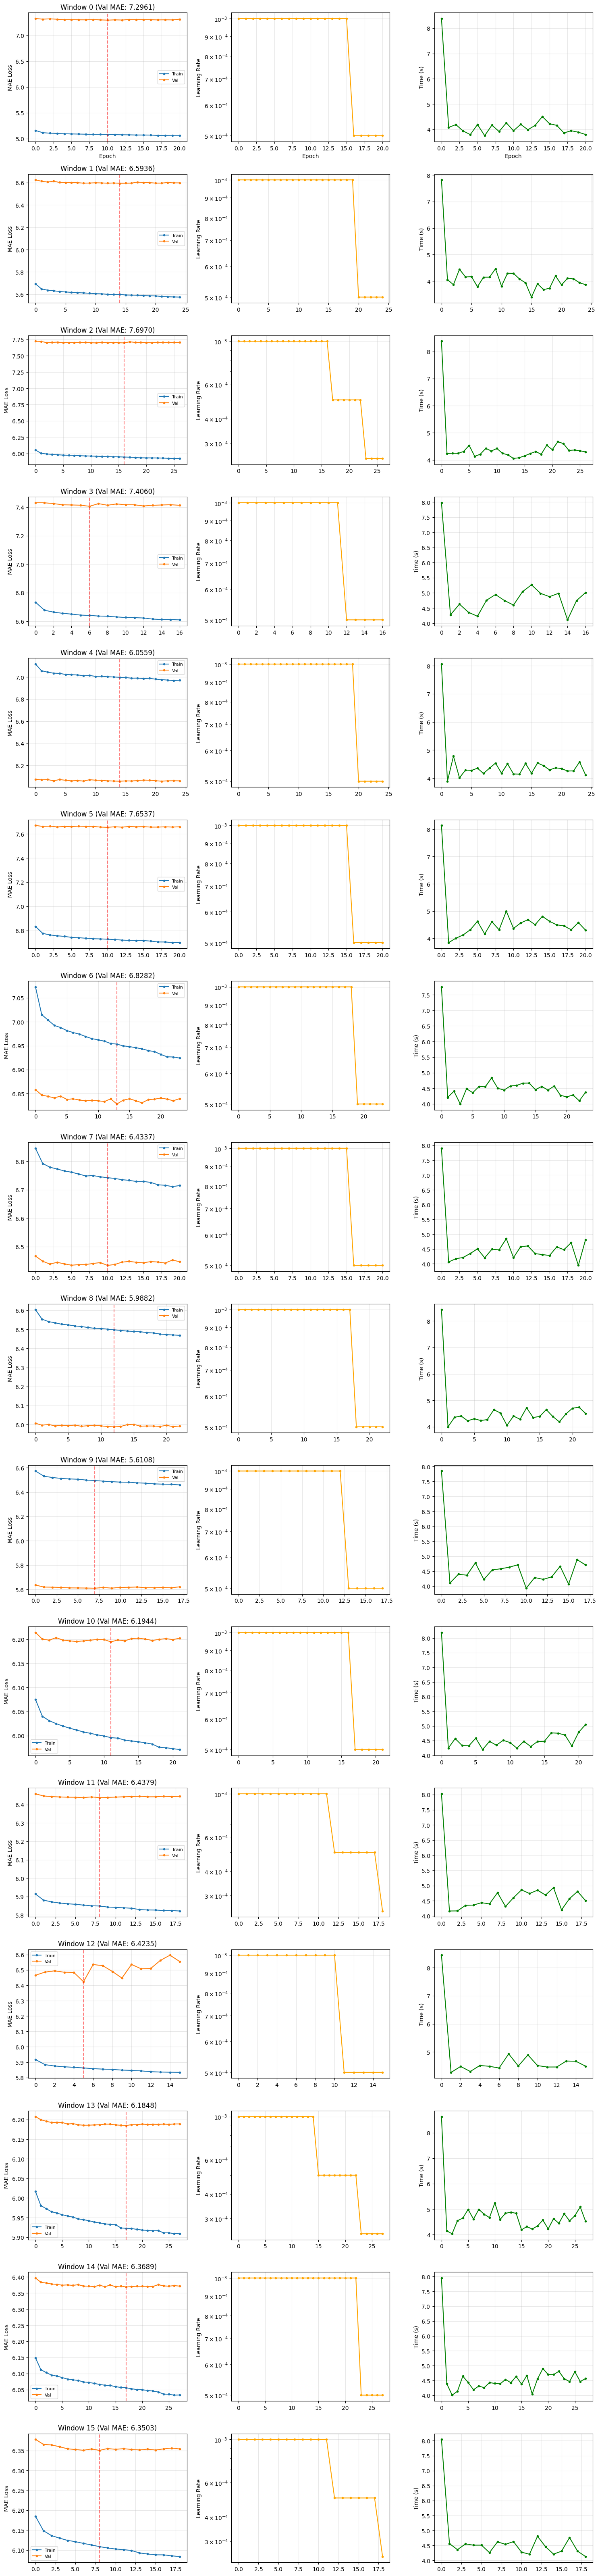

训练曲线已保存: /root/TCN/output_windows/training_curves.png


In [17]:
from matplotlib.ticker import MaxNLocator
# 绘制所有窗口的训练曲线
n_plots = len(all_results)
fig, axes = plt.subplots(n_plots, 3, figsize=(15, 4*n_plots))
if n_plots == 1:
    axes = axes.reshape(1, -1)

    
for idx, result in enumerate(all_results):
    history = result['history']
    
    n_epochs = len(history['train_loss'])

    # 损失曲线
    axes[idx, 0].plot(history['train_loss'], label='Train', marker='o', markersize=3)
    axes[idx, 0].plot(history['val_loss'], label='Val', marker='o', markersize=3)
    axes[idx, 0].axvline(result['best_epoch'], color='red', linestyle='--', alpha=0.5)
    axes[idx, 0].set_ylabel('MAE Loss')
    axes[idx, 0].set_title(f'Window {idx} (Val MAE: {result["best_val_loss"]:.4f})')
    axes[idx, 0].legend(fontsize=8)
    axes[idx, 0].grid(True, alpha=0.3)
    
    # 学习率曲线
    axes[idx, 1].plot(history['learning_rate'], marker='o', markersize=3, color='orange')
    axes[idx, 1].set_ylabel('Learning Rate')
    axes[idx, 1].set_yscale('log')
    axes[idx, 1].grid(True, alpha=0.3)
    
    # 每epoch耗时
    axes[idx, 2].plot(history['epoch_time'], marker='o', markersize=3, color='green')
    axes[idx, 2].set_ylabel('Time (s)')
    axes[idx, 2].grid(True, alpha=0.3)


    

    # 只给第一行设置 xlabel
    if idx == 0:
        axes[idx, 0].set_xlabel('Epoch')
        axes[idx, 1].set_xlabel('Epoch')
        axes[idx, 2].set_xlabel('Epoch')

plt.tight_layout()
plt.show()

# 保存图表
fig_path = OUTPUT_DIR / "training_curves.png"
fig.savefig(fig_path, dpi=150, bbox_inches='tight')
print(f"训练曲线已保存: {fig_path}")

## 7. 窗口间性能对比

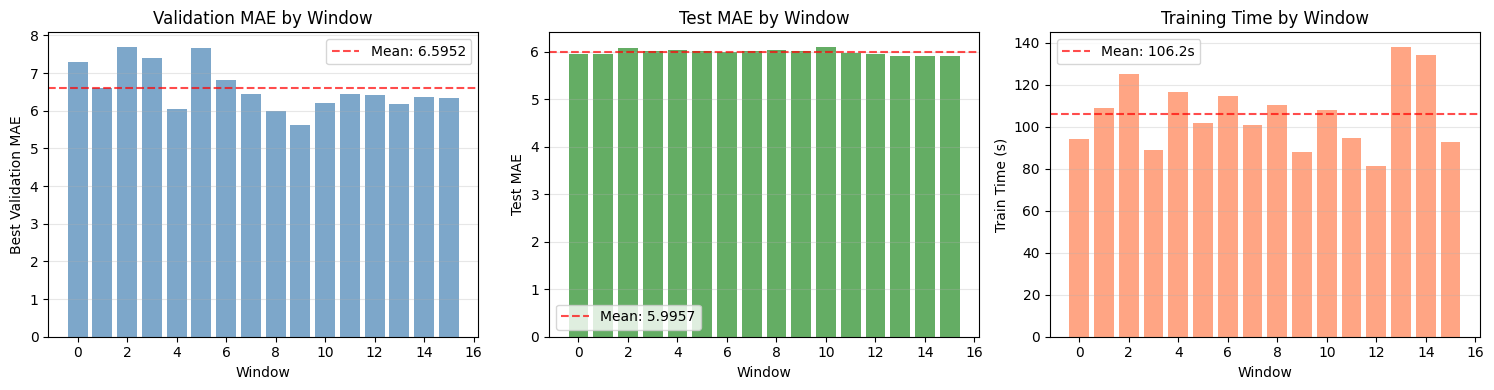

窗口对比图已保存: /root/TCN/output_windows/window_comparison.png


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 验证MAE对比
axes[0].bar(summary_df['Window'], summary_df['Best Val MAE'], alpha=0.7, color='steelblue')
axes[0].axhline(summary_df['Best Val MAE'].mean(), color='red', linestyle='--', alpha=0.7, 
             label=f'Mean: {summary_df["Best Val MAE"].mean():.4f}')
axes[0].set_xlabel('Window')
axes[0].set_ylabel('Best Validation MAE')
axes[0].set_title('Validation MAE by Window')
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# 测试MAE对比
axes[1].bar(summary_df['Window'], summary_df['Test MAE'], alpha=0.7, color='forestgreen')
axes[1].axhline(summary_df['Test MAE'].mean(), color='red', linestyle='--', alpha=0.7,
             label=f'Mean: {summary_df["Test MAE"].mean():.4f}')
axes[1].set_xlabel('Window')
axes[1].set_ylabel('Test MAE')
axes[1].set_title('Test MAE by Window')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')

# 训练时间对比
axes[2].bar(summary_df['Window'], summary_df['Train Time (s)'], alpha=0.7, color='coral')
axes[2].axhline(summary_df['Train Time (s)'].mean(), color='red', linestyle='--', alpha=0.7,
             label=f'Mean: {summary_df["Train Time (s)"].mean():.1f}s')
axes[2].set_xlabel('Window')
axes[2].set_ylabel('Train Time (s)')
axes[2].set_title('Training Time by Window')
axes[2].legend()
axes[2].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# 保存图表
fig_path = OUTPUT_DIR / "window_comparison.png"
fig.savefig(fig_path, dpi=150, bbox_inches='tight')
print(f"窗口对比图已保存: {fig_path}")

## 8. 模型集成分析

In [19]:
# ============================================================================
# 模型集成 - 多种集成策略对比
# ============================================================================

from scipy.stats import trim_mean

def calculate_weights(n_windows, method="uniform", val_maes=None, temperature=1.0):
    """
    计算集成权重
    
    Args:
        n_windows: 窗口数量
        method: 权重计算方式
            - "uniform": 等权重
            - "inverse_mae": 验证集 MAE 的倒数加权
            - "exponential_mae": 指数衰减的 MAE 倒数
            - "time_decay": 时间衰减（越近权重越高）
            - "time_mae": 时间衰减 * MAE 加权
        val_maes: 各窗口验证集 MAE
        temperature: 温度参数，控制权重分布的尖锐程度
    
    Returns:
        归一化的权重数组
    """
    if method == "uniform":
        weights = np.ones(n_windows)
    elif method == "time_decay":
        # 时间衰减：最近窗口权重最高
        indices = np.arange(n_windows)
        weights = np.exp(indices * temperature / n_windows)
    elif method == "inverse_mae":
        if val_maes is None:
            raise ValueError("val_maes 不能为空")
        # MAE 越小权重越高: w_i = 1 / mae_i
        weights = 1.0 / (val_maes + 1e-8)
    elif method == "exponential_mae":
        if val_maes is None:
            raise ValueError("val_maes 不能为空")
        # 指数形式的 MAE 倒数: w_i = exp(-mae_i / temperature)
        weights = np.exp(-val_maes / temperature)
    elif method == "time_mae":
        if val_maes is None:
            raise ValueError("val_maes 不能为空")
        # 时间衰减 * MAE 加权
        indices = np.arange(n_windows)
        time_weights = np.exp(indices * temperature / n_windows)
        mae_weights = 1.0 / (val_maes + 1e-8)
        weights = time_weights * mae_weights
    else:
        raise ValueError(f"未知的权重计算方式: {method}")
    
    # 归一化
    weights = weights / weights.sum()
    return weights


def ensemble_predictions(all_preds, method="mean", weights=None):
    """
    集成多个模型的预测
    
    Args:
        all_preds: {window_id: predictions_array}
        method: 集成方式
            - "mean": 算术平均
            - "weighted_mean": 加权平均
            - "median": 中位数
            - "trim_mean": 截尾平均（去掉最高最低各 10%）
        weights: 加权平均时的权重
    
    Returns:
        集成后的预测数组
    """
    pred_matrix = np.stack([all_preds[i] for i in sorted(all_preds.keys())], axis=0)
    
    if method == "mean":
        return pred_matrix.mean(axis=0)
    elif method == "weighted_mean":
        if weights is None:
            raise ValueError("weighted_mean 需要提供 weights")
        return (pred_matrix * weights[:, None]).sum(axis=0)
    elif method == "median":
        return np.median(pred_matrix, axis=0)
    elif method == "trim_mean":
        return trim_mean(pred_matrix, 0.1, axis=0)
    else:
        raise ValueError(f"未知的集成方式: {method}")


def calculate_metrics(predictions, targets):
    """计算评估指标"""
    errors = predictions - targets
    abs_errors = np.abs(errors)
    squared_errors = errors ** 2
    
    return {
        "mae": float(np.mean(abs_errors)),
        "rmse": float(np.sqrt(np.mean(squared_errors))),
        "bias": float(np.mean(errors)),
        "median_ae": float(np.median(abs_errors)),
        "std_error": float(np.std(errors)),
    }


# 准备集成数据
print("="*60)
print("准备集成数据...")
print("="*60)

# 收集所有窗口的预测和实际值
all_predictions = {}
all_actuals = None
val_maes = []

for result in all_results:
    idx = result['window_idx']
    all_predictions[idx] = result['predictions']
    if all_actuals is None:
        all_actuals = result['actuals']
    val_maes.append(result['best_val_loss'])

val_maes = np.array(val_maes)
n_windows = len(all_predictions)

print(f"集成窗口数: {n_windows}")
print(f"预测样本数: {len(all_actuals)}")

# 计算各种权重
print("\n" + "="*60)
print("权重计算")
print("="*60)

weight_methods = ["uniform", "time_decay", "inverse_mae", "exponential_mae", "time_mae"]
all_weights = {}

for method in weight_methods:
    try:
        weights = calculate_weights(n_windows, method=method, val_maes=val_maes)
        all_weights[method] = weights
        print(f"\n{method} 权重:")
        for i, wid in enumerate(sorted(all_predictions.keys())):
            print(f"  Window {wid}: {weights[i]:.4f}")
    except Exception as e:
        print(f"计算 {method} 权重失败: {e}")

# 集成预测
print("\n" + "="*60)
print("集成结果")
print("="*60)

ensemble_methods = ["mean", "weighted_mean", "median", "trim_mean"]
results = []

for ens_method in ensemble_methods:
    print(f"\n{ens_method} 集成:")
    
    for weight_name, weights in all_weights.items():
        if ens_method == "mean" and weight_name != "uniform":
            continue
        if ens_method == "weighted_mean" and weight_name == "uniform":
            continue
        
        try:
            if ens_method == "weighted_mean":
                preds = ensemble_predictions(all_predictions, method="weighted_mean", weights=weights)
                name = f"{ens_method}_{weight_name}"
            else:
                preds = ensemble_predictions(all_predictions, method=ens_method)
                name = ens_method
            
            metrics = calculate_metrics(preds, all_actuals)
            results.append({
                "method": name,
                "mae": metrics["mae"],
                "rmse": metrics["rmse"],
                "bias": metrics["bias"],
                "median_ae": metrics["median_ae"],
            })
            
            print(f"  {name}: MAE={metrics['mae']:.6f}, RMSE={metrics['rmse']:.6f}, Bias={metrics['bias']:.6f}")
        
        except Exception as e:
            print(f"  {name}_{weight_name} 失败: {e}")

# 汇总对比
print("\n" + "="*60)
print("结果汇总 (按 MAE 排序)")
print("="*60)

results_df = pd.DataFrame(results).sort_values("mae")
print("\n" + results_df.to_string(index=False))

# 保存结果
ensemble_dir = OUTPUT_DIR / "ensemble"
ensemble_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(ensemble_dir / "ensemble_results.csv", index=False)
print(f"\n结果已保存到 {ensemble_dir / 'ensemble_results.csv'}")

准备集成数据...
集成窗口数: 16
预测样本数: 889199

权重计算

uniform 权重:
  Window 0: 0.0625
  Window 1: 0.0625
  Window 2: 0.0625
  Window 3: 0.0625
  Window 4: 0.0625
  Window 5: 0.0625
  Window 6: 0.0625
  Window 7: 0.0625
  Window 8: 0.0625
  Window 9: 0.0625
  Window 10: 0.0625
  Window 11: 0.0625
  Window 12: 0.0625
  Window 13: 0.0625
  Window 14: 0.0625
  Window 15: 0.0625

time_decay 权重:
  Window 0: 0.0375
  Window 1: 0.0400
  Window 2: 0.0425
  Window 3: 0.0453
  Window 4: 0.0482
  Window 5: 0.0513
  Window 6: 0.0546
  Window 7: 0.0581
  Window 8: 0.0619
  Window 9: 0.0659
  Window 10: 0.0701
  Window 11: 0.0746
  Window 12: 0.0795
  Window 13: 0.0846
  Window 14: 0.0900
  Window 15: 0.0958

inverse_mae 权重:
  Window 0: 0.0561
  Window 1: 0.0620
  Window 2: 0.0531
  Window 3: 0.0552
  Window 4: 0.0675
  Window 5: 0.0534
  Window 6: 0.0599
  Window 7: 0.0636
  Window 8: 0.0683
  Window 9: 0.0729
  Window 10: 0.0660
  Window 11: 0.0635
  Window 12: 0.0637
  Window 13: 0.0661
  Window 14: 0.0642
  Wi


单模型 vs 集成模型对比
单模型平均 MAE: 5.995706 ± 0.058094
单模型最佳 MAE: 5.910764
集成最佳 MAE: 5.907605 (weighted_mean_time_decay)
集成提升: 1.47%


/tmp/ipykernel_5170/4290366057.py:34: UserWarning: Glyph 31383 (\N{CJK UNIFIED IDEOGRAPH-7A97}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5170/4290366057.py:34: UserWarning: Glyph 21475 (\N{CJK UNIFIED IDEOGRAPH-53E3}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5170/4290366057.py:34: UserWarning: Glyph 21333 (\N{CJK UNIFIED IDEOGRAPH-5355}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5170/4290366057.py:34: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5170/4290366057.py:34: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5170/4290366057.py:34: UserWarning: Glyph 38598 (\N{CJK UNIFIED IDEOGRAPH-96C6}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_5170/4290366057.py:34: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}

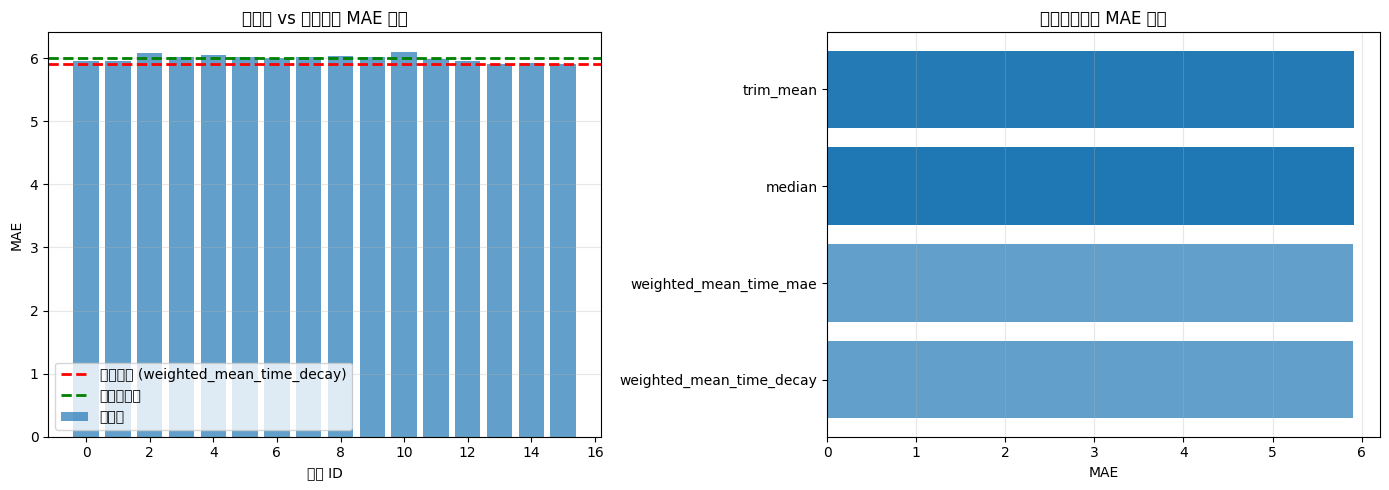

/tmp/ipykernel_5170/4290366057.py:39: UserWarning: Glyph 21333 (\N{CJK UNIFIED IDEOGRAPH-5355}) missing from font(s) DejaVu Sans.
  fig.savefig(fig_path, dpi=150, bbox_inches='tight')
/tmp/ipykernel_5170/4290366057.py:39: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  fig.savefig(fig_path, dpi=150, bbox_inches='tight')
/tmp/ipykernel_5170/4290366057.py:39: UserWarning: Glyph 22411 (\N{CJK UNIFIED IDEOGRAPH-578B}) missing from font(s) DejaVu Sans.
  fig.savefig(fig_path, dpi=150, bbox_inches='tight')
/tmp/ipykernel_5170/4290366057.py:39: UserWarning: Glyph 38598 (\N{CJK UNIFIED IDEOGRAPH-96C6}) missing from font(s) DejaVu Sans.
  fig.savefig(fig_path, dpi=150, bbox_inches='tight')
/tmp/ipykernel_5170/4290366057.py:39: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  fig.savefig(fig_path, dpi=150, bbox_inches='tight')
/tmp/ipykernel_5170/4290366057.py:39: UserWarning: Glyph 23545 (\N{CJK UNIFIED I


对比图已保存到 /root/TCN/output_windows/ensemble/ensemble_comparison.png


In [20]:
# 单模型 vs 集成模型对比
print("\n" + "="*60)
print("单模型 vs 集成模型对比")
print("="*60)

single_model_maes = [r['test_mae'] for r in all_results]
print(f"单模型平均 MAE: {np.mean(single_model_maes):.6f} ± {np.std(single_model_maes):.6f}")
print(f"单模型最佳 MAE: {np.min(single_model_maes):.6f}")
print(f"集成最佳 MAE: {results_df.iloc[0]['mae']:.6f} ({results_df.iloc[0]['method']})")
improvement = (np.mean(single_model_maes) - results_df.iloc[0]['mae']) / np.mean(single_model_maes) * 100
print(f"集成提升: {improvement:.2f}%")

# 可视化对比
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 单模型 MAE 分布
axes[0].bar(range(len(single_model_maes)), single_model_maes, alpha=0.7, label='单模型')
axes[0].axhline(y=results_df.iloc[0]['mae'], color='red', linestyle='--', linewidth=2, 
               label=f'最佳集成 ({results_df.iloc[0]["method"]})')
axes[0].axhline(y=np.mean(single_model_maes), color='green', linestyle='--', linewidth=2, label='单模型平均')
axes[0].set_title('单模型 vs 集成模型 MAE 对比')
axes[0].set_xlabel('窗口 ID')
axes[0].set_ylabel('MAE')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# 不同集成方式对比
top_results = results_df.head(10)
axes[1].barh(top_results['method'], top_results['mae'], alpha=0.7)
axes[1].set_title('不同集成方式 MAE 对比')
axes[1].set_xlabel('MAE')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

# 保存对比图
fig_path = ensemble_dir / "ensemble_comparison.png"
fig.savefig(fig_path, dpi=150, bbox_inches='tight')
print(f"\n对比图已保存到 {fig_path}")